### Exercise 1

Make an application which is capable of translating RNA molecules into proteins, using the genetic code table.
Translation starts at the first start codon (AUG) and ends at the first stop codon (UAA, UAG, UGA).
Input: S = GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG

In [1]:
# Standard genetic code: RNA codon -> amino acid (one-letter code, "*" = stop)
GENETIC_CODE = {
    "UUU": "F", "UUC": "F", "UUA": "L", "UUG": "L",
    "UCU": "S", "UCC": "S", "UCA": "S", "UCG": "S",
    "UAU": "Y", "UAC": "Y", "UAA": "*", "UAG": "*",
    "UGU": "C", "UGC": "C", "UGA": "*", "UGG": "W",

    "CUU": "L", "CUC": "L", "CUA": "L", "CUG": "L",
    "CCU": "P", "CCC": "P", "CCA": "P", "CCG": "P",
    "CAU": "H", "CAC": "H", "CAA": "Q", "CAG": "Q",
    "CGU": "R", "CGC": "R", "CGA": "R", "CGG": "R",

    "AUU": "I", "AUC": "I", "AUA": "I", "AUG": "M",
    "ACU": "T", "ACC": "T", "ACA": "T", "ACG": "T",
    "AAU": "N", "AAC": "N", "AAA": "K", "AAG": "K",
    "AGU": "S", "AGC": "S", "AGA": "R", "AGG": "R",

    "GUU": "V", "GUC": "V", "GUA": "V", "GUG": "V",
    "GCU": "A", "GCC": "A", "GCA": "A", "GCG": "A",
    "GAU": "D", "GAC": "D", "GAA": "E", "GAG": "E",
    "GGU": "G", "GGC": "G", "GGA": "G", "GGG": "G",
}

AMINO_ACID_NAMES = {
    "A": "Ala", "R": "Arg", "N": "Asn", "D": "Asp", "C": "Cys",
    "Q": "Gln", "E": "Glu", "G": "Gly", "H": "His", "I": "Ile",
    "L": "Leu", "K": "Lys", "M": "Met", "F": "Phe", "P": "Pro",
    "S": "Ser", "T": "Thr", "W": "Trp", "Y": "Tyr", "V": "Val",
    "*": "Stop",
}

START_CODON = "AUG"


def translate(rna):
    """Translate an mRNA from the first AUG up to (not including) the first stop codon."""
    rna = rna.upper()
    invalid = set(rna) - set("ACGU")
    if invalid:
        raise ValueError(f"Invalid nucleotides: {invalid}")
    start = rna.find(START_CODON)
    if start == -1:
        raise ValueError("No start codon (AUG) found")

    codons, protein = [], []
    for i in range(start, len(rna) - 2, 3):
        codon = rna[i:i + 3]
        amino_acid = GENETIC_CODE[codon]
        codons.append(codon)
        if amino_acid == "*":
            break
        protein.append(amino_acid)
    return start, codons, "".join(protein)


S = "GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG"
start, codons, protein = translate(S)

print(f"mRNA: {S}")
print(f"Start codon AUG at position {start + 1}")
print()
print("Codon -> amino acid:")
for codon in codons:
    aa = GENETIC_CODE[codon]
    print(f"{codon} -> {AMINO_ACID_NAMES[aa]:4} ({aa})")
print()
print(f"Protein: {protein}")
print(f"         {'-'.join(AMINO_ACID_NAMES[aa] for aa in protein)}")

mRNA: GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG
Start codon AUG at position 3

Codon -> amino acid:
AUG -> Met  (M)
GCC -> Ala  (A)
AUU -> Ile  (I)
GUA -> Val  (V)
AUG -> Met  (M)
GGC -> Gly  (G)
CGC -> Arg  (R)
UGA -> Stop (*)

Protein: MAIVMGR
         Met-Ala-Ile-Val-Met-Gly-Arg


### Exercise 2

Download from NCBI a viral or bacterial genome as a FASTA file (here: *Escherichia coli* str. K-12 substr. MG1655, NC_000913.3).
Make an application which is able to scan the entire genome using a sliding window of 3 positions (letters), and measure the frequency of each codon.
There are 64 codons in total; show the top 10 codons with the highest frequency and make a chart of their frequencies.

Genome: Escherichia coli str. K-12 substr. MG1655 (NC_000913.3)
Length = 4,641,652 nucleotides
Windows scanned = 4,641,650, distinct codons = 64 / 64

Top 10 codons:
 1. CGC (Arg)  115,734  ->  2.49%
 2. GCG (Ala)  114,670  ->  2.47%
 3. TTT (Phe)  109,862  ->  2.37%
 4. AAA (Lys)  108,964  ->  2.35%
 5. CAG (Gln)  104,850  ->  2.26%
 6. CTG (Leu)  102,957  ->  2.22%
 7. GCA (Ala)   96,071  ->  2.07%
 8. TGC (Cys)   95,270  ->  2.05%
 9. GCC (Ala)   93,028  ->  2.00%
10. GGC (Gly)   92,189  ->  1.99%


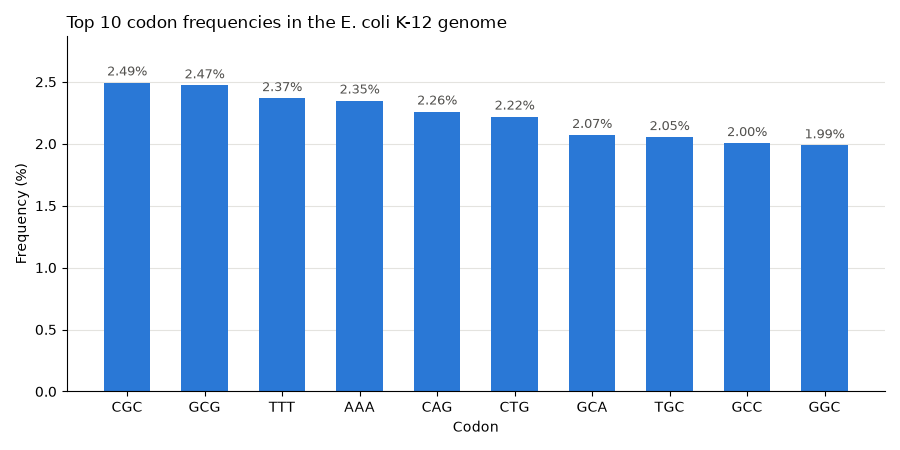

In [2]:
from collections import Counter
from itertools import product

import matplotlib.pyplot as plt


def read_fasta(path):
    """Return the sequence from a FASTA file (header lines starting with '>' are skipped)."""
    with open(path) as f:
        return "".join(line.strip() for line in f if not line.startswith(">")).upper()


def codon_frequencies(seq, window=3):
    """Slide a window of 3 letters over the sequence, one position at a time, and count each codon."""
    counts = Counter(seq[i:i + window] for i in range(len(seq) - window + 1))
    all_codons = ["".join(c) for c in product("ACGT", repeat=window)]
    return {codon: counts[codon] for codon in all_codons}


genome = read_fasta("ecoli_K12_MG1655.fasta")
counts = codon_frequencies(genome)
total = sum(counts.values())
top10 = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10]

print("Genome: Escherichia coli str. K-12 substr. MG1655 (NC_000913.3)")
print(f"Length = {len(genome):,} nucleotides")
print(f"Windows scanned = {total:,}, distinct codons = {sum(1 for c in counts.values() if c)} / 64")
print()
print("Top 10 codons:")
for rank, (codon, count) in enumerate(top10, 1):
    aa = GENETIC_CODE[codon.replace("T", "U")]
    print(f"{rank:2d}. {codon} ({AMINO_ACID_NAMES[aa]})  {count:7,d}  ->  {100 * count / total:.2f}%")

codons = [codon for codon, _ in top10]
percents = [100 * count / total for _, count in top10]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(codons, percents, width=0.6, color="#2a78d6")
ax.bar_label(bars, labels=[f"{p:.2f}%" for p in percents], padding=3, fontsize=9, color="#52514e")
ax.set_title("Top 10 codon frequencies in the E. coli K-12 genome", loc="left", fontsize=12)
ax.set_xlabel("Codon")
ax.set_ylabel("Frequency (%)")
ax.set_ylim(0, max(percents) * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Exercise 3

Analyze the top 10 most frequent codons of the bacterium: find which amino acids they encode,
and based on them recommend what to eat (foods to limit, which are rich in those amino acids, and foods that are low in them).

In [3]:
# Foods that are rich sources of each amino acid
FOODS_RICH_IN = {
    "A": ["meat", "poultry", "fish", "eggs", "gelatin"],
    "R": ["nuts", "pumpkin seeds", "poultry", "soy", "chickpeas"],
    "F": ["meat", "fish", "eggs", "dairy", "soy"],
    "K": ["meat", "fish", "eggs", "dairy", "lentils", "beans"],
    "Q": ["meat", "poultry", "fish", "eggs", "dairy", "tofu"],
    "L": ["dairy", "meat", "poultry", "soy", "nuts"],
    "C": ["eggs", "poultry", "garlic", "onions", "oats"],
    "G": ["gelatin", "bone broth", "meat", "fish"],
}

# Low-protein foods: they contain little of any amino acid
LOW_PROTEIN_FOODS = ["fruits (apples, berries, grapes)", "leafy greens and cucumbers",
                     "tomatoes and carrots", "rice", "potatoes", "olive oil"]


def amino_acid_profile(top_codons):
    """Group the top codons by the amino acid they encode and add up their counts."""
    profile = Counter()
    for codon, count in top_codons:
        profile[GENETIC_CODE[codon.replace("T", "U")]] += count
    return profile.most_common()


profile = amino_acid_profile(top10)
top10_total = sum(count for _, count in top10)

print("Amino acids encoded by the top 10 codons:")
for aa, count in profile:
    codons_for_aa = [c for c, _ in top10 if GENETIC_CODE[c.replace("T", "U")] == aa]
    print(f"{AMINO_ACID_NAMES[aa]} ({aa})  {100 * count / top10_total:5.1f}%  <- {', '.join(codons_for_aa)}")

# Score each food by how much of the bacterium's preferred amino acids it supplies
food_scores = Counter()
for aa, count in profile:
    for food in FOODS_RICH_IN[aa]:
        food_scores[food] += count / top10_total

print()
print("Foods to limit (rich in the amino acids E. coli uses most):")
for food, score in food_scores.most_common(8):
    print(f"  - {food:15} score = {score:.2f}")

print()
print("Recommended foods (low in these amino acids):")
for food in LOW_PROTEIN_FOODS:
    print(f"  + {food}")

Amino acids encoded by the top 10 codons:
Ala (A)   29.4%  <- GCG, GCA, GCC
Arg (R)   11.2%  <- CGC
Phe (F)   10.6%  <- TTT
Lys (K)   10.5%  <- AAA
Gln (Q)   10.1%  <- CAG
Leu (L)   10.0%  <- CTG
Cys (C)    9.2%  <- TGC
Gly (G)    8.9%  <- GGC

Foods to limit (rich in the amino acids E. coli uses most):
  - meat            score = 0.80
  - eggs            score = 0.70
  - poultry         score = 0.70
  - fish            score = 0.70
  - dairy           score = 0.41
  - gelatin         score = 0.38
  - soy             score = 0.32
  - nuts            score = 0.21

Recommended foods (low in these amino acids):
  + fruits (apples, berries, grapes)
  + leafy greens and cucumbers
  + tomatoes and carrots
  + rice
  + potatoes
  + olive oil
